# 04 — Random Forest, MLP and Autoencoder
Same 5-fold stratified CV on training data as notebook 03, so all models sit in one fair comparison table.
- **Random Forest** (bagging): no handling vs class weights (SMOTE + RF is very slow and SMOTE did not help XGBoost).
- **MLP** (Keras, supervised): Dense 64 → 32 → 1 with class weights and early stopping.
- **Autoencoder** (Keras, unsupervised): trained on legit rows only; reconstruction error is the fraud score.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import PrecisionRecallDisplay

from src import config
from src.preprocess import load_data, train_test
from src.train import cv_compare
from src.deep import cv_deep

df = load_data(verbose=False)
X_train, X_test, y_train, y_test = train_test(df)  # X_test stays untouched

## Random Forest

In [2]:
rf = cv_compare(X_train, y_train, models=("rf",), techniques=("none", "class_weight"),
                results_path=config.RESULTS_DIR / "cv_results_rf.csv")

  rf | none         | PR-AUC 0.8365 ± 0.0330 | recall 0.778 | precision 0.943 | 367.4s


  rf | class_weight | PR-AUC 0.8346 ± 0.0333 | recall 0.754 | precision 0.943 | 238.6s


## MLP (deep learning, supervised)

In [3]:
mlp_row, mlp_oof = cv_deep(X_train, y_train, "mlp")

mlp fold 1: PR-AUC 0.7451 | recall 0.893 | precision 0.043


mlp fold 2: PR-AUC 0.7412 | recall 0.880 | precision 0.056


mlp fold 3: PR-AUC 0.6609 | recall 0.816 | precision 0.081


mlp fold 4: PR-AUC 0.6862 | recall 0.908 | precision 0.074


mlp fold 5: PR-AUC 0.7605 | recall 0.974 | precision 0.069


## Autoencoder (deep learning, anomaly detection)
Precision / recall are at an error threshold = 99.5th percentile of legit training errors (no fraud labels used to set it).

In [4]:
ae_row, ae_oof = cv_deep(X_train, y_train, "autoencoder")

autoencoder fold 1: PR-AUC 0.2660 | recall 0.560 | precision 0.148


autoencoder fold 2: PR-AUC 0.2493 | recall 0.613 | precision 0.168


autoencoder fold 3: PR-AUC 0.2004 | recall 0.526 | precision 0.169


autoencoder fold 4: PR-AUC 0.2605 | recall 0.632 | precision 0.170


autoencoder fold 5: PR-AUC 0.2987 | recall 0.750 | precision 0.188


## Full comparison table (all models, CV on training data)

In [5]:
lr_xgb = pd.read_csv(config.RESULTS_DIR / "cv_results_lr_xgb.csv")
dummy = {"model": "dummy", "technique": "none", "pr_auc_mean": y_train.mean(), "pr_auc_std": 0.0,
         "roc_auc_mean": 0.5, "roc_auc_std": 0.0, "recall_mean": 0.0, "recall_std": 0.0,
         "precision_mean": 0.0, "precision_std": 0.0, "f1_mean": 0.0, "f1_std": 0.0}
allres = pd.concat([lr_xgb, rf, pd.DataFrame([mlp_row, ae_row, dummy])], ignore_index=True)
allres.to_csv(config.RESULTS_DIR / "cv_results_all.csv", index=False)

def fmt(r, k):
    return f"{r[k + '_mean']:.3f} ± {r[k + '_std']:.3f}"

table = pd.DataFrame({
    "model": allres.model, "technique": allres.technique,
    "PR-AUC": [fmt(r, "pr_auc") for _, r in allres.iterrows()],
    "Recall": [fmt(r, "recall") for _, r in allres.iterrows()],
    "Precision": [fmt(r, "precision") for _, r in allres.iterrows()],
    "F1": [fmt(r, "f1") for _, r in allres.iterrows()],
    "ROC-AUC": [fmt(r, "roc_auc") for _, r in allres.iterrows()],
    "_sort": allres.pr_auc_mean,
}).sort_values("_sort", ascending=False).drop(columns="_sort").reset_index(drop=True)
table.to_csv(config.RESULTS_DIR / "comparison_table.csv", index=False)
table

,model,technique,PR-AUC,Recall,Precision,F1,ROC-AUC
0,xgb,none,0.848 ± 0.026,0.791 ± 0.062,0.943 ± 0.030,0.858 ± 0.030,0.983 ± 0.005
1,xgb,class_weight,0.842 ± 0.029,0.831 ± 0.044,0.879 ± 0.037,0.853 ± 0.029,0.979 ± 0.006
2,rf,none,0.837 ± 0.033,0.778 ± 0.088,0.943 ± 0.019,0.849 ± 0.055,0.948 ± 0.021
3,xgb,smote,0.835 ± 0.036,0.839 ± 0.042,0.591 ± 0.026,0.693 ± 0.023,0.976 ± 0.007
4,rf,class_weight,0.835 ± 0.033,0.754 ± 0.077,0.943 ± 0.027,0.835 ± 0.044,0.952 ± 0.021
5,lr,class_weight,0.754 ± 0.026,0.918 ± 0.025,0.060 ± 0.007,0.113 ± 0.012,0.981 ± 0.008
6,lr,none,0.753 ± 0.031,0.614 ± 0.055,0.868 ± 0.022,0.717 ± 0.033,0.976 ± 0.014
7,lr,smote,0.752 ± 0.027,0.907 ± 0.034,0.057 ± 0.006,0.107 ± 0.011,0.981 ± 0.008
8,xgb,undersample,0.732 ± 0.076,0.907 ± 0.032,0.048 ± 0.004,0.091 ± 0.007,0.980 ± 0.008
9,mlp,class_weight,0.719 ± 0.038,0.894 ± 0.051,0.064 ± 0.013,0.120 ± 0.023,0.968 ± 0.016


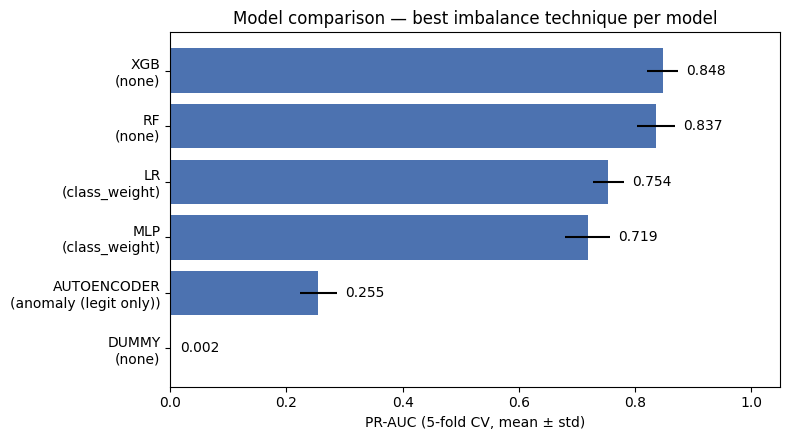

In [6]:
best_per_model = allres.loc[allres.groupby("model").pr_auc_mean.idxmax()].sort_values("pr_auc_mean")
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{m.upper()}\n({t})" for m, t in zip(best_per_model.model, best_per_model.technique)]
bars = ax.barh(labels, best_per_model.pr_auc_mean, xerr=best_per_model.pr_auc_std, color="#4c72b0")
ax.bar_label(bars, fmt="%.3f", padding=6)
ax.set_xlim(0, 1.05); ax.set_xlabel("PR-AUC (5-fold CV, mean ± std)")
ax.set_title("Model comparison — best imbalance technique per model")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "04_model_comparison.png", dpi=150); plt.show()

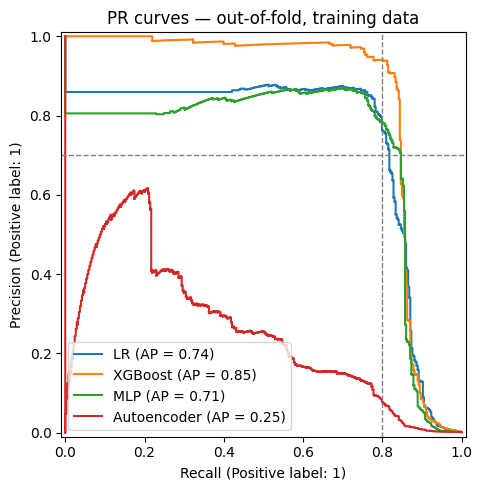

In [7]:
oof_prev = pd.read_csv(config.RESULTS_DIR / "oof_lr_xgb.csv")
fig, ax = plt.subplots(figsize=(7, 5))
for name, score in [("LR", oof_prev.oof_lr), ("XGBoost", oof_prev.oof_xgb), ("MLP", mlp_oof), ("Autoencoder", ae_oof)]:
    PrecisionRecallDisplay.from_predictions(y_train, score, ax=ax, name=name)
ax.axhline(config.TARGET_PRECISION, ls="--", c="grey", lw=1)
ax.axvline(config.TARGET_RECALL, ls="--", c="grey", lw=1)
ax.set_title("PR curves — out-of-fold, training data")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "04_pr_curves_all.png", dpi=150); plt.show()